[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/kulinskij-tech/ClassMech/blob/main/ClassMech_Python/classmech_parametricres.ipynb)


# Small oscillations: normal modes

## Lagrangian of an oscillatory system

In [1]:
import numpy as np
import sympy as sp
import matplotlib.pyplot as plt
import ipywidgets as widgets
from IPython.display import display


def animate_parameter(draw,minimum,maximum,value,step,label):
    draw(value)
    slider=widgets.FloatSlider(value=value,min=minimum,max=maximum,step=step,
                               description=label,continuous_update=False)
    play=widgets.Play(value=0,min=0,max=int(round((maximum-minimum)/step)),step=1,interval=120,repeat=False)
    def advance(change):
        slider.value=min(maximum,minimum+change['new']*step)
    play.observe(advance,names='value')
    view=widgets.interactive_output(lambda parameter: draw(parameter),{'parameter':slider})
    display(widgets.VBox([widgets.HBox([play,slider]),view]))
    return slider,play,view

m1,m2,l,l1,l2,g,k,k1,k2,k3,a=sp.symbols('m_1 m_2 l l_1 l_2 g k k_1 k_2 k_3 a',positive=True)
phi1,phi2,phi3,phi4,phid1,phid2,phid3,phid4=sp.symbols('phi_1 phi_2 phi_3 phi_4 phidot_1 phidot_2 phidot_3 phidot_4',real=True)
q1,q2,qd1,qd2=sp.symbols('q_1 q_2 qdot_1 qdot_2',real=True)
def modes2(M,K):
    D=M.inv()*K
    disc=sp.factor((D[0,0]-D[1,1])**2+4*D[0,1]*D[1,0])
    values=[sp.factor((sp.trace(D)+sign*sp.sqrt(disc))/2) for sign in (-1,1)]
    vectors=[sp.Matrix([1,sp.factor((value-D[0,0])/D[0,1])]) for value in values]
    return values,vectors
def rectangular_series(f,x,y):
    return sp.expand(sp.series(sp.series(f,x,0,3).removeO(),y,0,3).removeO())

Expanding around a stable equilibrium in generalized coordinates gives

$$
L=\frac{1}{2}\sum {m}_{ij}{\dot{q}}_{i}{\dot{q}}_{j}-\frac{1}{2}\sum {k}_{ij}{q}_{i}{q}_{j}
$$

The EoM are

$$
\frac{d}{dt}\left(\frac{\partial L}{\partial  {\dot{q}}_{i} }\right)-\frac{\partial L}{\partial  {q}_{i} }=\sum {m}_{ij}{\ddot{q}}_{j}+\sum {k}_{ij}{q}_{j}=0
$$

In matrix form, these linear differential equations are

$$
M\ddot{\mathbf{q}}+K \mathbf{q}=0
$$

The mass matrix is positive definite, and the stiffness matrix is positive definite at a strict stable equilibrium without zero modes. A suitable change of coordinates diagonalizes both quadratic forms.

$$
\mathbf{q}=A \mathbf{Q}\mathbf{ }\mathbf{\Rightarrow }\ddot{\mathbf{Q}}+{A}^{-1}{M}^{-1}K A \mathbf{Q}=0\\ {A}^{-1}{M}^{-1}K A - \text{diagonal matrix of eigenfrequencies} \left(\begin{matrix}{\omega }_{1}^{2} & 0 & ... & 0\\ 0 & {\omega }_{2}^{2} & ... & ...\\ ... & ... & ... & 0\\ 0 & ... & 0 & {\omega }_{s}^{2}\end{matrix}\right)
$$

${\omega }_{i}\leftrightarrow {Q}_{i}$ are corresponding eigenmodes of oscillatory system.

## Example 1

Let’s find eigenmodes and frequencies of small plane oscillations  of the double pendulum


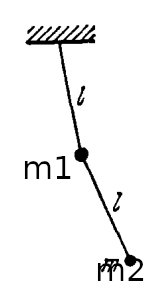


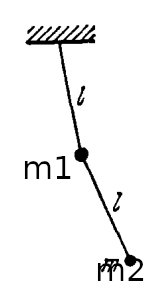

Lagrange function (introducing obvious angle displacements):

$$
L=\frac{{m}_{1}{l}^{2}}{2}{\dot{\varphi }}_{1}^{2}+\frac{{m}_{2}}{2}\left({\dot{x}}^{2}+{\dot{y}}^{2}\right)-{m}_{1}gl\left(1-\cos{{\varphi}_{1}}\right)-{m}_{2} g\left(2l- y\right)\\ x=l\left(\sin{{\varphi }_{1}}+\sin{{\varphi }_{2}}\right), y=l\left(\cos{{\varphi }_{1}}+\cos{{\varphi }_{2}}\right)\\ \dot{x}=l\left({\dot{\varphi }}_{1}\cos{{\varphi }_{1}}+{\dot{\varphi }}_{2}\cos{{\varphi }_{2}}\right), \dot{y}=-l\left({\dot{\varphi }}_{1}\sin{{\varphi }_{1}}+{\dot{\varphi }}_{2}\sin{{\varphi }_{2}}\right)
$$

Lagrange and energy functions:

In [2]:
vx=l*(phid1*sp.cos(phi1)+phid2*sp.cos(phi2)); vy=-l*(phid1*sp.sin(phi1)+phid2*sp.sin(phi2))
T=m1*l*l*phid1**2/2+m2*(vx*vx+vy*vy)/2
U=m1*g*l*(1-sp.cos(phi1))+m2*g*l*(2-sp.cos(phi1)-sp.cos(phi2))
lgrng11=T-U; enrg11=T+U

Series expansion near equilibrium $\left({\varphi }_{1}={\varphi }_{2}=0\right)$:

In [3]:
enrng12=rectangular_series(enrg11,phi1,phi2)
display(enrng12)

g*l*m_1*phi_1**2/2 + g*l*m_2*phi_1**2/2 + g*l*m_2*phi_2**2/2 + l**2*m_1*phidot_1**2/2 + l**2*m_2*phi_1**2*phi_2**2*phidot_1*phidot_2/4 - l**2*m_2*phi_1**2*phidot_1*phidot_2/2 + l**2*m_2*phi_1*phi_2*phidot_1*phidot_2 - l**2*m_2*phi_2**2*phidot_1*phidot_2/2 + l**2*m_2*phidot_1**2/2 + l**2*m_2*phidot_1*phidot_2 + l**2*m_2*phidot_2**2/2

Stiffness matrix:

In [4]:
# Both source matrices include a factor 1/2; it cancels in M^{-1}K.
kmtrx=sp.simplify(sp.hessian(enrng12,(phi1,phi2)).subs({phi1:0,phi2:0,phid1:0,phid2:0})/2)
display(kmtrx)

Matrix([
[g*l*(m_1 + m_2)/2,         0],
[                0, g*l*m_2/2]])

Mass matrix:

In [5]:
mmtrx=sp.simplify(sp.hessian(enrng12,(phid1,phid2)).subs({phi1:0,phi2:0})/2)
display(mmtrx)

Matrix([
[l**2*(m_1 + m_2)/2, l**2*m_2/2],
[        l**2*m_2/2, l**2*m_2/2]])

Eigenvalues :

In [6]:
double_eigenvalues,double_eigenvectors=modes2(mmtrx,kmtrx)
display(double_eigenvalues)

[g*(m_1 - sqrt(m_2)*sqrt(m_1 + m_2) + m_2)/(l*m_1),
 g*(m_1 + sqrt(m_2)*sqrt(m_1 + m_2) + m_2)/(l*m_1)]

Eigenvectors (normal modes):

In [7]:
eigv=double_eigenvectors
display(*eigv)

Matrix([
[                        1],
[sqrt(m_1 + m_2)/sqrt(m_2)]])

Matrix([
[                         1],
[-sqrt(m_1 + m_2)/sqrt(m_2)]])

## Example 2


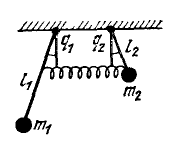


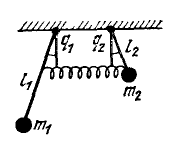

In [8]:
coupling=a
T=m1*l1*l1*qd1**2/2+m2*l2*l2*qd2**2/2
U=m1*g*l1*(1-sp.cos(q1))+m2*g*l2*(1-sp.cos(q2))+coupling*(sp.sin(q1)-sp.sin(q2))**2/2
lgrng21=T-U; enrg21=T+U

In [9]:
enrg22=rectangular_series(enrg21,q1,q2)
display(enrg22)

a*q_1**2/2 - a*q_1*q_2 + a*q_2**2/2 + g*l_1*m_1*q_1**2/2 + g*l_2*m_2*q_2**2/2 + l_1**2*m_1*qdot_1**2/2 + l_2**2*m_2*qdot_2**2/2

In [10]:
kmtrx=sp.simplify(sp.hessian(enrg22,(q1,q2)).subs({q1:0,q2:0,qd1:0,qd2:0}))
mmtrx=sp.simplify(sp.hessian(enrg22,(qd1,qd2)).subs({q1:0,q2:0}))
display(kmtrx,mmtrx)

Matrix([
[a + g*l_1*m_1,            -a],
[           -a, a + g*l_2*m_2]])

Matrix([
[l_1**2*m_1,          0],
[         0, l_2**2*m_2]])

In [11]:
eigv2,eigvc2=modes2(mmtrx,kmtrx)
# At infinite coupling the finite-frequency mode has q1=q2.
finite_limit=g*(l1*m1+l2*m2)/(l1**2*m1+l2**2*m2)
display(finite_limit,sp.oo)

g*(l_1*m_1 + l_2*m_2)/(l_1**2*m_1 + l_2**2*m_2)

oo

In [12]:
display(*eigvc2)

Matrix([
[                                                                                                                                                                                                                                                                                                                                                                                                                    1],
[-(a*l_1**2*m_1 - a*l_2**2*m_2 + g*l_1**2*l_2*m_1*m_2 - g*l_1*l_2**2*m_1*m_2 - sqrt(a**2*l_1**4*m_1**2 + 2*a**2*l_1**2*l_2**2*m_1*m_2 + a**2*l_2**4*m_2**2 + 2*a*g*l_1**4*l_2*m_1**2*m_2 - 2*a*g*l_1**3*l_2**2*m_1**2*m_2 - 2*a*g*l_1**2*l_2**3*m_1*m_2**2 + 2*a*g*l_1*l_2**4*m_1*m_2**2 + g**2*l_1**4*l_2**2*m_1**2*m_2**2 - 2*g**2*l_1**3*l_2**3*m_1**2*m_2**2 + g**2*l_1**2*l_2**4*m_1**2*m_2**2))/(2*a*l_2**2*m_2)]])

Matrix([
[                                                                                                                                                                                                                                                                                                                                                                                                                    1],
[-(a*l_1**2*m_1 - a*l_2**2*m_2 + g*l_1**2*l_2*m_1*m_2 - g*l_1*l_2**2*m_1*m_2 + sqrt(a**2*l_1**4*m_1**2 + 2*a**2*l_1**2*l_2**2*m_1*m_2 + a**2*l_2**4*m_2**2 + 2*a*g*l_1**4*l_2*m_1**2*m_2 - 2*a*g*l_1**3*l_2**2*m_1**2*m_2 - 2*a*g*l_1**2*l_2**3*m_1*m_2**2 + 2*a*g*l_1*l_2**4*m_1*m_2**2 + g**2*l_1**4*l_2**2*m_1**2*m_2**2 - 2*g**2*l_1**3*l_2**3*m_1**2*m_2**2 + g**2*l_1**2*l_2**4*m_1**2*m_2**2))/(2*a*l_2**2*m_2)]])

## Example 3


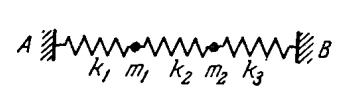


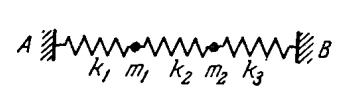

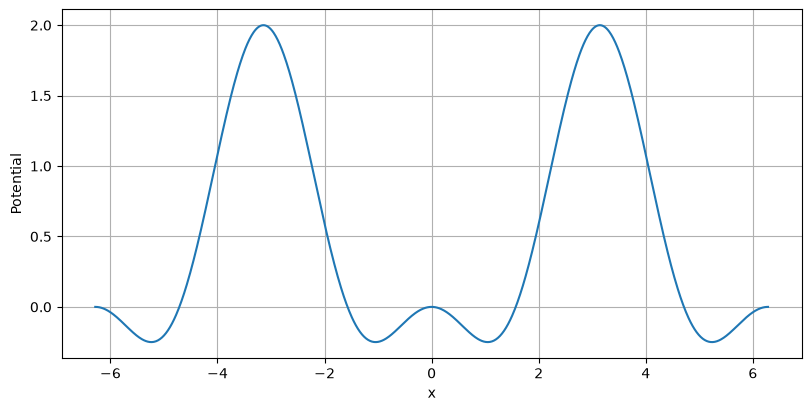

In [13]:
x=np.linspace(-2*np.pi,2*np.pi,1000)
fig,ax=plt.subplots(figsize=(8,4),layout='constrained'); ax.plot(x,-np.cos(x)+np.cos(x)**2); ax.set(xlabel='x',ylabel='Potential'); ax.grid(); plt.show()

In [14]:
# The source contains a commented-out installation command for the Wolfram Rubi package.
# All calculations here use the open-source dependencies imported above.

In [15]:
# The original checks the location of its optional Rubi package.
# This translation uses SymPy instead and has no Rubi dependency.
display({'Symbolic backend':'SymPy','Version':sp.__version__})

{'Symbolic backend': 'SymPy', 'Version': '1.14.0'}

[Back to the course contents](https://colab.research.google.com/github/kulinskij-tech/ClassMech/blob/main/ClassMech_Python/classmech_TOC.ipynb)